# CODE TO CLASSIFY TRAFFIC SIGNS USING LE-NET ARCHITECTURE IN KERAS

# STEP 0: PROBLEM STATEMENT

- In this case study, you have been provided with images of traffic signs and the goal is to train a Deep Network to classify them
- The dataset contains 43 different classes of images. 
- Classes are as listed below: 

    - ( 0, b'Speed limit (20km/h)') ( 1, b'Speed limit (30km/h)')
    - ( 2, b'Speed limit (50km/h)') ( 3, b'Speed limit (60km/h)')
    - ( 4, b'Speed limit (70km/h)') ( 5, b'Speed limit (80km/h)')
    - ( 6, b'End of speed limit (80km/h)') ( 7, b'Speed limit (100km/h)')
    - ( 8, b'Speed limit (120km/h)') ( 9, b'No passing')
    - (10, b'No passing for vehicles over 3.5 metric tons')
    - (11, b'Right-of-way at the next intersection') (12, b'Priority road')
    - (13, b'Yield') (14, b'Stop') (15, b'No vehicles')
    - (16, b'Vehicles over 3.5 metric tons prohibited') (17, b'No entry')
    - (18, b'General caution') (19, b'Dangerous curve to the left')
    - (20, b'Dangerous curve to the right') (21, b'Double curve')
    - (22, b'Bumpy road') (23, b'Slippery road')
    - (24, b'Road narrows on the right') (25, b'Road work')
    - (26, b'Traffic signals') (27, b'Pedestrians') (28, b'Children crossing')
    - (29, b'Bicycles crossing') (30, b'Beware of ice/snow')
    - (31, b'Wild animals crossing')
    - (32, b'End of all speed and passing limits') (33, b'Turn right ahead')
    - (34, b'Turn left ahead') (35, b'Ahead only') (36, b'Go straight or right')
    - (37, b'Go straight or left') (38, b'Keep right') (39, b'Keep left')
    - (40, b'Roundabout mandatory') (41, b'End of no passing')
    - (42, b'End of no passing by vehicles over 3.5 metric tons')

- The network used is called Le-Net that was presented by Yann LeCun
http://yann.lecun.com/exdb/publis/pdf/lecun-01a.pdf


Citation

J. Stallkamp, M. Schlipsing, J. Salmen, and C. Igel. The German Traffic Sign Recognition Benchmark: A multi-class classification competition. In Proceedings of the IEEE International Joint Conference on Neural Networks, pages 1453–1460. 2011. 

@inproceedings{Stallkamp-IJCNN-2011,
    author = {Johannes Stallkamp and Marc Schlipsing and Jan Salmen and Christian Igel},
    booktitle = {IEEE International Joint Conference on Neural Networks},
    title = {The {G}erman {T}raffic {S}ign {R}ecognition {B}enchmark: A multi-class classification competition},
    year = {2011},
    pages = {1453--1460}
}

# STEP 1: IMPORT LIBRARIES AND DATASET

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import pickle

In [2]:
with open("./traffic-signs-data/train.p", mode='rb') as training_data:
    train = pickle.load(training_data)
with open("./traffic-signs-data/valid.p", mode='rb') as validation_data:
    valid = pickle.load(validation_data)
with open("./traffic-signs-data/test.p", mode='rb') as testing_data:
    test = pickle.load(testing_data)

In [3]:
X_train, y_train = train['features'], train['labels']
X_validation, y_validation = valid['features'], valid['labels']
X_test, y_test = test['features'], test['labels']

In [4]:
X_train.shape

(34799, 32, 32, 3)

In [5]:
y_train.shape

(34799,)

In [6]:
X_validation.shape

(4410, 32, 32, 3)

In [7]:
y_validation.shape

(4410,)

In [8]:
X_test.shape

(12630, 32, 32, 3)

In [9]:
y_test.shape

(12630,)

# STEP 2: IMAGE EXPLORATION

np.uint8(36)

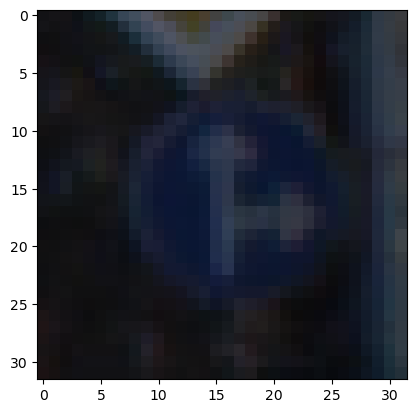

In [10]:
i = 1000
plt.imshow(X_train[i])
y_train[i]

np.uint8(1)

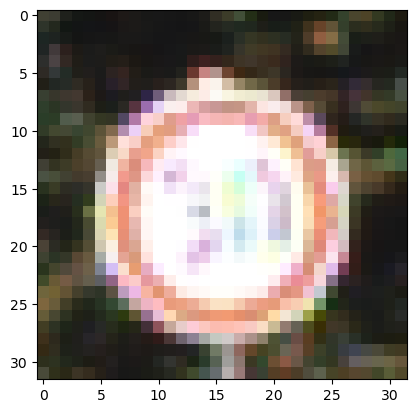

In [11]:
i = 300
plt.imshow(X_validation[i])
y_validation[i]

np.uint8(22)

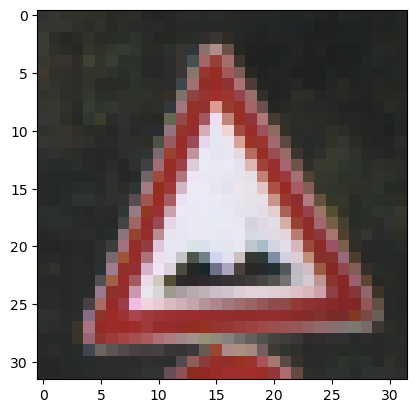

In [12]:
i = 500
plt.imshow(X_test[i])
y_test[i]

# STEP 2.1: CLASS DISTRIBUTION ANALYSIS

In [13]:
unique_classes, class_counts = np.unique(y_train, return_counts=True)

print("Number of classes:", len(unique_classes))

for class_id, count in zip(unique_classes, class_counts):
    print(f"Class {class_id}: {count} images")

Number of classes: 43
Class 0: 180 images
Class 1: 1980 images
Class 2: 2010 images
Class 3: 1260 images
Class 4: 1770 images
Class 5: 1650 images
Class 6: 360 images
Class 7: 1290 images
Class 8: 1260 images
Class 9: 1320 images
Class 10: 1800 images
Class 11: 1170 images
Class 12: 1890 images
Class 13: 1920 images
Class 14: 690 images
Class 15: 540 images
Class 16: 360 images
Class 17: 990 images
Class 18: 1080 images
Class 19: 180 images
Class 20: 300 images
Class 21: 270 images
Class 22: 330 images
Class 23: 450 images
Class 24: 240 images
Class 25: 1350 images
Class 26: 540 images
Class 27: 210 images
Class 28: 480 images
Class 29: 240 images
Class 30: 390 images
Class 31: 690 images
Class 32: 210 images
Class 33: 599 images
Class 34: 360 images
Class 35: 1080 images
Class 36: 330 images
Class 37: 180 images
Class 38: 1860 images
Class 39: 270 images
Class 40: 300 images
Class 41: 210 images
Class 42: 210 images


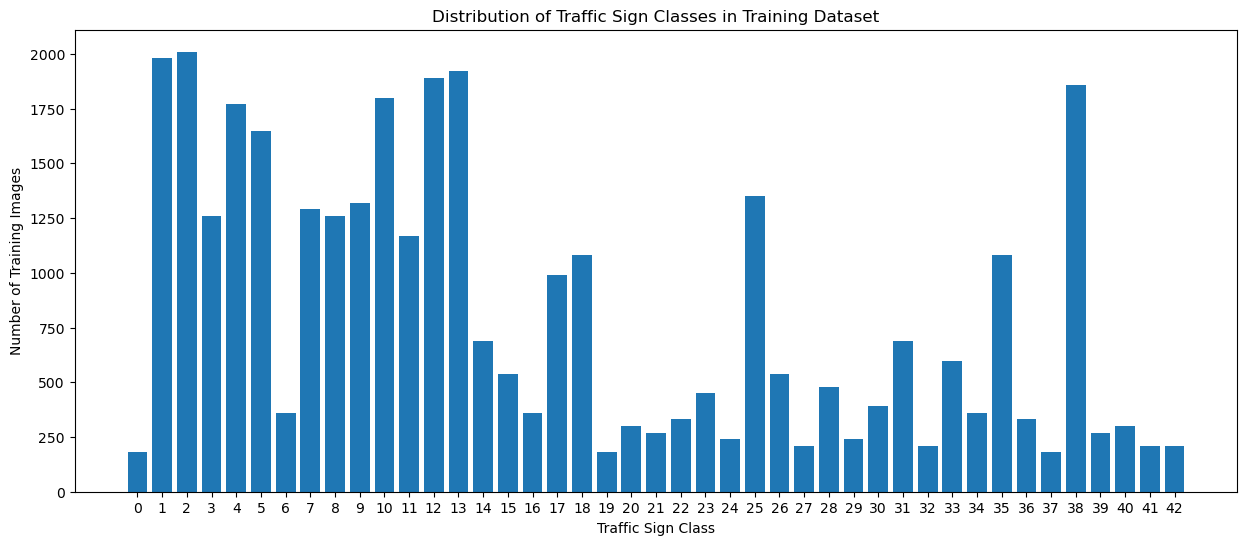

In [14]:
plt.figure(figsize=(15, 6))

plt.bar(unique_classes, class_counts)

plt.xlabel("Traffic Sign Class")
plt.ylabel("Number of Training Images")
plt.title("Distribution of Traffic Sign Classes in Training Dataset")

plt.xticks(unique_classes)
plt.show()

# Step 2.2 — Display examples from different classes

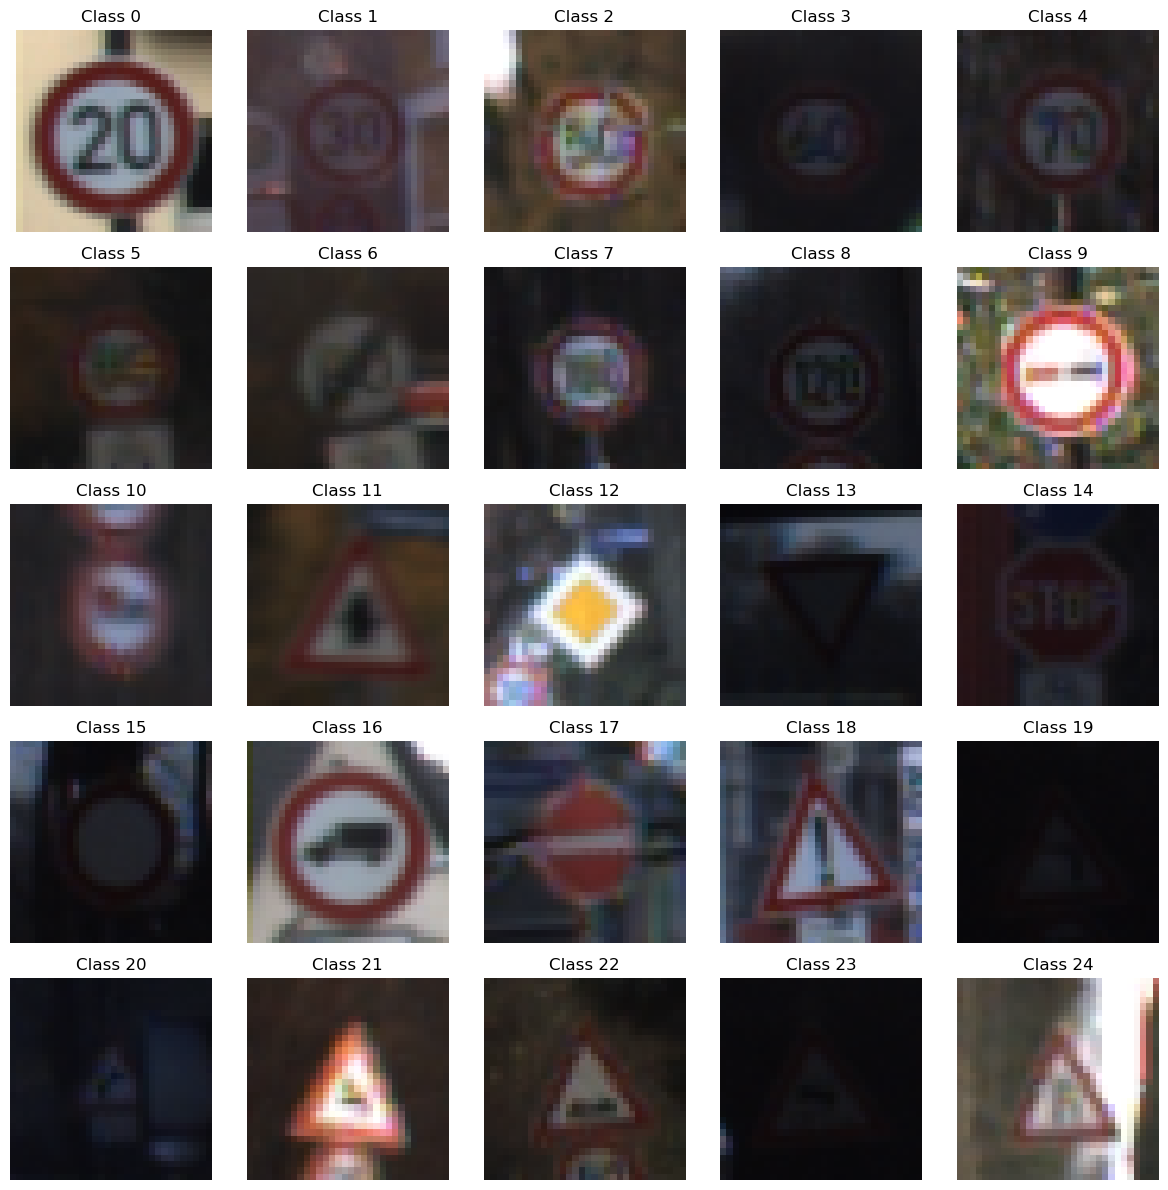

In [15]:
fig, axes = plt.subplots(5, 5, figsize=(12, 12))
axes = axes.ravel()

for class_id in range(25):
    
    index = np.where(y_train == class_id)[0][0]
    
    axes[class_id].imshow(X_train[index])
    axes[class_id].set_title(f"Class {class_id}")
    axes[class_id].axis("off")

plt.tight_layout()
plt.show()

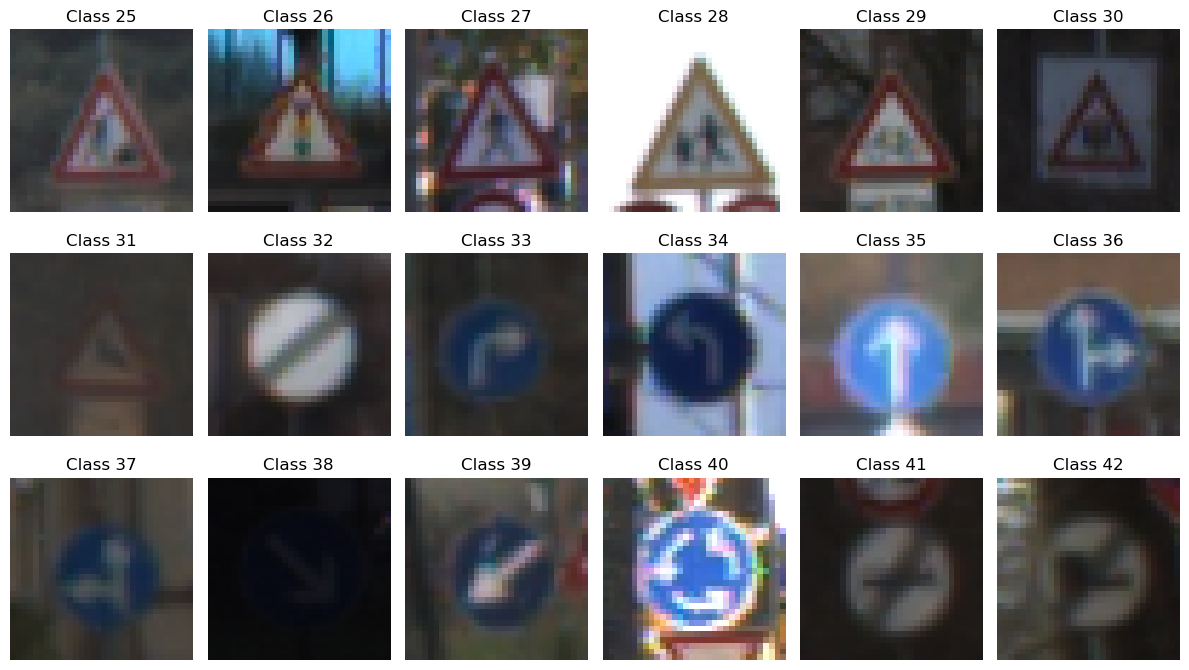

In [16]:
remaining_classes = range(25, 43)

fig, axes = plt.subplots(3, 6, figsize=(12, 7))
axes = axes.ravel()

for i, class_id in enumerate(remaining_classes):
    
    index = np.where(y_train == class_id)[0][0]
    
    axes[i].imshow(X_train[index])
    axes[i].set_title(f"Class {class_id}")
    axes[i].axis("off")

plt.tight_layout()
plt.show()

# STEP 3: DATA PEPARATION

In [17]:
from sklearn.utils import shuffle
X_train, y_train = shuffle(X_train, y_train)

In [18]:
X_train_gray = np.sum(X_train/3, axis = 3, keepdims= True)
X_validation_gray = np.sum(X_validation/3, axis = 3, keepdims= True)
X_test_gray = np.sum(X_test/3, axis = 3, keepdims= True)

In [19]:
X_train_gray.shape

(34799, 32, 32, 1)

In [20]:
X_train_gray_norm = (X_train_gray - 128)/128
X_validation_gray_norm = (X_validation_gray - 128)/128
X_test_gray_norm = (X_test_gray - 128)/128

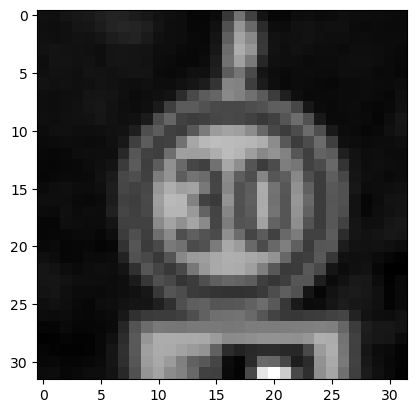

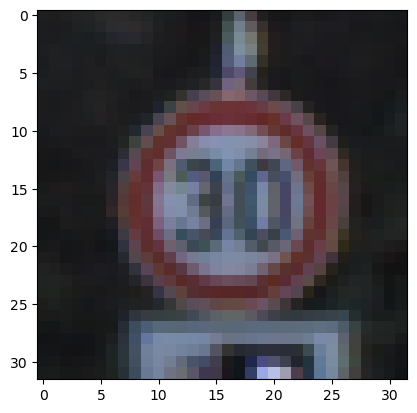

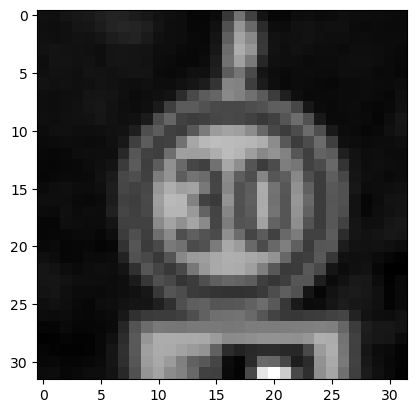

In [21]:
i = 1060
plt.imshow(X_train_gray[i].squeeze(), cmap= 'gray')
plt.figure()
plt.imshow(X_train[i])
plt.figure()
plt.imshow(X_train_gray_norm[i].squeeze(), cmap= 'gray')

# STEP 4: MODEL TRAINING

The model consists of the following layers: 

- STEP 1: THE FIRST CONVOLUTIONAL LAYER #1
    - Input = 32x32x1
    - Output = 28x28x6
    - Output = (Input-filter+1)/Stride* => (32-5+1)/1=28
    - Used a 5x5 Filter with input depth of 3 and output depth of 6
    - Apply a RELU Activation function to the output
    - pooling for input, Input = 28x28x6 and Output = 14x14x6


    * Stride is the amount by which the kernel is shifted when the kernel is passed over the image.

- STEP 2: THE SECOND CONVOLUTIONAL LAYER #2
    - Input = 14x14x6
    - Output = 10x10x16
    - Layer 2: Convolutional layer with Output = 10x10x16
    - Output = (Input-filter+1)/strides => 10 = 14-5+1/1
    - Apply a RELU Activation function to the output
    - Pooling with Input = 10x10x16 and Output = 5x5x16

- STEP 3: FLATTENING THE NETWORK
    - Flatten the network with Input = 5x5x16 and Output = 400

- STEP 4: FULLY CONNECTED LAYER
    - Layer 3: Fully Connected layer with Input = 400 and Output = 120
    - Apply a RELU Activation function to the output

- STEP 5: ANOTHER FULLY CONNECTED LAYER
    - Layer 4: Fully Connected Layer with Input = 120 and Output = 84
    - Apply a RELU Activation function to the output

- STEP 6: FULLY CONNECTED LAYER
    - Layer 5: Fully Connected layer with Input = 84 and Output = 43

In [22]:
from keras.models import Sequential

from keras.layers import Conv2D, MaxPooling2D, AveragePooling2D, Dense, Flatten, Dropout
from keras.optimizers import Adam
from keras.callbacks import TensorBoard

In [23]:
cnn_model = Sequential()
cnn_model.add(Conv2D(filters= 6, kernel_size=(5, 5), activation= 'relu', input_shape= (32,32,1)))
cnn_model.add(AveragePooling2D(2, 2))

cnn_model.add(Conv2D(filters= 16, kernel_size=(5, 5), activation= 'relu'))
cnn_model.add(AveragePooling2D(2, 2))

cnn_model.add(Flatten())

cnn_model.add(Dense(units= 120, activation= 'relu'))
cnn_model.add(Dense(units= 84, activation= 'relu'))
cnn_model.add(Dense(units= 43, activation= 'softmax'))

C:\Users\amill\AppData\Roaming\Python\Python313\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [24]:
from keras.optimizers import Adam
from keras.losses import SparseCategoricalCrossentropy

cnn_model.compile(
    optimizer=Adam(),
    loss=SparseCategoricalCrossentropy(),
    metrics=['accuracy']
)

In [25]:
history = cnn_model.fit(
    X_train_gray_norm,
    y_train,
    batch_size=500,
    epochs= 50,
    verbose=1,
    validation_data=(X_validation_gray_norm, y_validation)
)

Epoch 1/50
70/70 ━━━━━━━━━━━━━━━━━━━━ 3s 22ms/step - accuracy: 0.1808 - loss: 3.1503 - val_accuracy: 0.2855 - val_loss: 2.6462
Epoch 2/50
70/70 ━━━━━━━━━━━━━━━━━━━━ 1s 21ms/step - accuracy: 0.5374 - loss: 1.6603 - val_accuracy: 0.5599 - val_loss: 1.4350
Epoch 3/50
70/70 ━━━━━━━━━━━━━━━━━━━━ 1s 19ms/step - accuracy: 0.7281 - loss: 0.9448 - val_accuracy: 0.6882 - val_loss: 1.0394
Epoch 4/50
70/70 ━━━━━━━━━━━━━━━━━━━━ 1s 21ms/step - accuracy: 0.8178 - loss: 0.6629 - val_accuracy: 0.7478 - val_loss: 0.8451
Epoch 5/50
70/70 ━━━━━━━━━━━━━━━━━━━━ 1s 20ms/step - accuracy: 0.8564 - loss: 0.5320 - val_accuracy: 0.7821 - val_loss: 0.7676
Epoch 6/50
70/70 ━━━━━━━━━━━━━━━━━━━━ 1s 19ms/step - accuracy: 0.8856 - loss: 0.4381 - val_accuracy: 0.7875 - val_loss: 0.7320
Epoch 7/50
70/70 ━━━━━━━━━━━━━━━━━━━━ 1s 18ms/step - accuracy: 0.8997 - loss: 0.3772 - val_accuracy: 0.8147 - val_loss: 0.6492
Epoch 8/50
70/70 ━━━━━━━━━━━━━━━━━━━━ 1s 19ms/step - accuracy: 0.9173 - loss: 0.3208 - val_accuracy: 0.8270 - v

# STEP 5: MODEL EVALUATION

In [26]:
score = cnn_model.evaluate(X_test_gray_norm, y_test)
print('Test Accuracy: {} %'.format(score[1]*100))

395/395 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8717 - loss: 1.1560
Test Accuracy: 87.16548085212708 %


In [27]:
history.history.keys()

dict_keys(['accuracy', 'loss', 'val_accuracy', 'val_loss'])

In [28]:
accuracy = history.history['accuracy']
loss = history.history['loss']
val_accuracy = history.history['val_accuracy']
val_loss = history.history['val_loss']

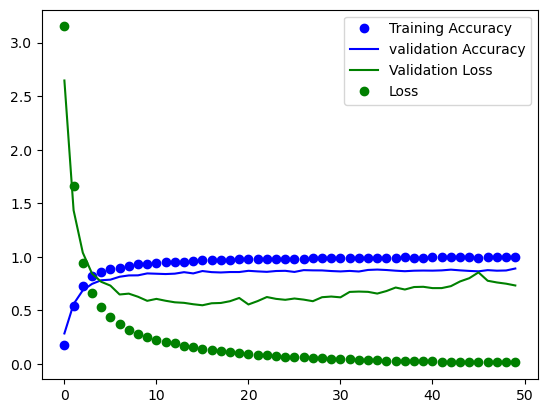

In [29]:
epochs = range(len(accuracy))

plt.plot(epochs, accuracy, 'bo', label= 'Training Accuracy')
plt.plot(epochs, val_accuracy, 'b', label= 'validation Accuracy')
plt.plot(epochs, val_loss, 'g', label= 'Validation Loss')
plt.plot(epochs, loss, 'go', label= 'Loss')
plt.legend()
plt.show()

In [30]:
predictions = cnn_model.predict(X_test_gray_norm)
predicted_classes = np.argmax(predictions, axis=1)
confidence_scores = np.max(predictions, axis=1) * 100
y_true = y_test

395/395 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step


In [31]:
class_names = [
    'Speed limit (20km/h)',
    'Speed limit (30km/h)',
    'Speed limit (50km/h)',
    'Speed limit (60km/h)',
    'Speed limit (70km/h)',
    'Speed limit (80km/h)',
    'End of speed limit (80km/h)',
    'Speed limit (100km/h)',
    'Speed limit (120km/h)',
    'No passing',
    'No passing for vehicles over 3.5 metric tons',
    'Right-of-way at the next intersection',
    'Priority road',
    'Yield',
    'Stop',
    'No vehicles',
    'Vehicles over 3.5 metric tons prohibited',
    'No entry',
    'General caution',
    'Dangerous curve to the left',
    'Dangerous curve to the right',
    'Double curve',
    'Bumpy road',
    'Slippery road',
    'Road narrows on the right',
    'Road work',
    'Traffic signals',
    'Pedestrians',
    'Children crossing',
    'Bicycles crossing',
    'Beware of ice/snow',
    'Wild animals crossing',
    'End of all speed and passing limits',
    'Turn right ahead',
    'Turn left ahead',
    'Ahead only',
    'Go straight or right',
    'Go straight or left',
    'Keep right',
    'Keep left',
    'Roundabout mandatory',
    'End of no passing',
    'End of no passing by vehicles over 3.5 metric tons'
]

In [32]:
from sklearn.metrics import classification_report

report = classification_report(
    y_true,
    predicted_classes,
    target_names=class_names,
    digits=4
)

print(report)

                                                    precision    recall  f1-score   support

                              Speed limit (20km/h)     0.7077    0.7667    0.7360        60
                              Speed limit (30km/h)     0.8783    0.9125    0.8951       720
                              Speed limit (50km/h)     0.8333    0.9067    0.8685       750
                              Speed limit (60km/h)     0.8803    0.9156    0.8976       450
                              Speed limit (70km/h)     0.9373    0.8833    0.9095       660
                              Speed limit (80km/h)     0.9239    0.8476    0.8841       630
                       End of speed limit (80km/h)     0.9744    0.7600    0.8539       150
                             Speed limit (100km/h)     0.9201    0.8444    0.8806       450
                             Speed limit (120km/h)     0.8571    0.8533    0.8552       450
                                        No passing     0.8967    0.9583    0.92

In [33]:
# Find incorrectly classified images
incorrect_indices = np.where(predicted_classes != y_true)[0]

print("Total test images:", len(y_true))
print("Correct predictions:", np.sum(predicted_classes == y_true))
print("Incorrect predictions:", len(incorrect_indices))

Total test images: 12630
Correct predictions: 11009
Incorrect predictions: 1621


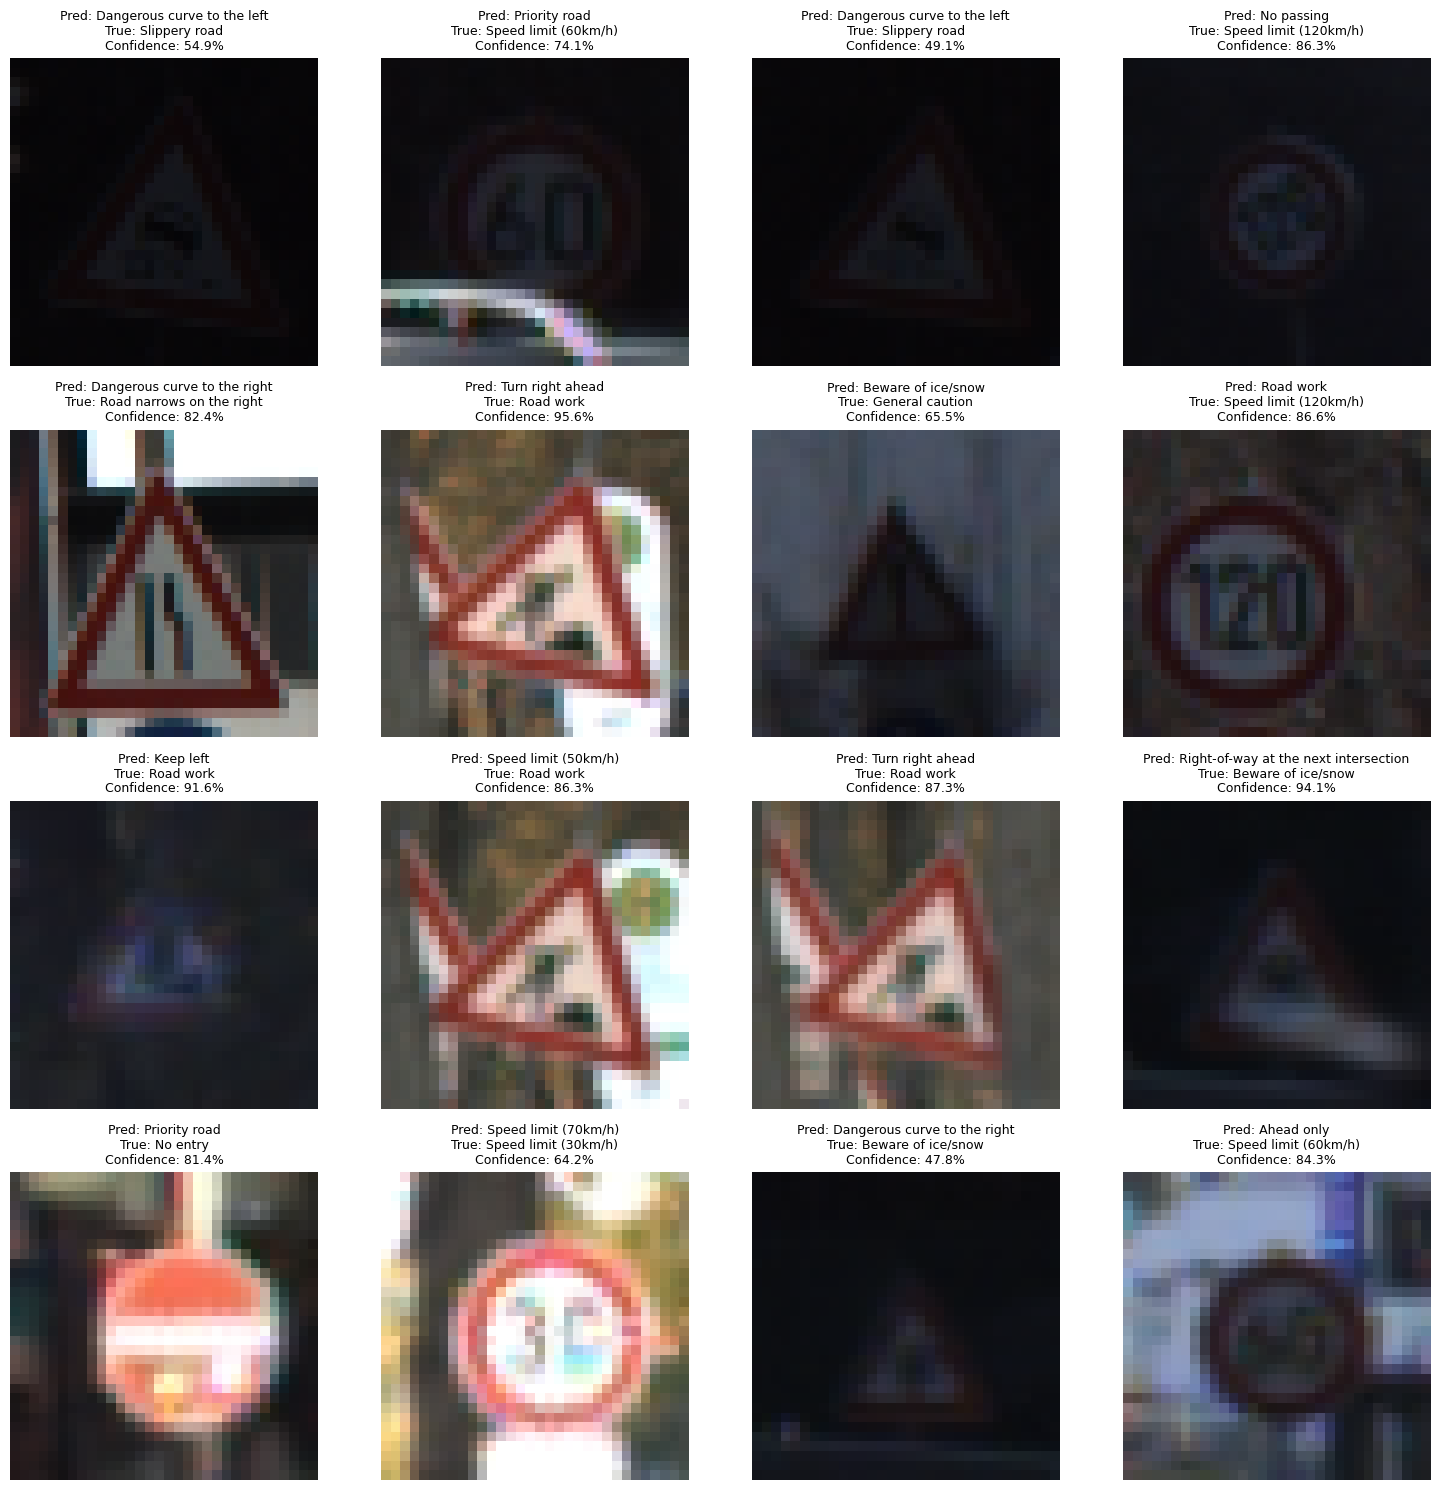

In [34]:
fig, axes = plt.subplots(4, 4, figsize=(15, 15))
axes = axes.ravel()

for i in range(16):
    idx = incorrect_indices[i]

    axes[i].imshow(X_test[idx])

    predicted_id = predicted_classes[idx]
    actual_id = y_true[idx]

    axes[i].set_title(
        f"Pred: {class_names[predicted_id]}\n"
        f"True: {class_names[actual_id]}\n"
        f"Confidence: {confidence_scores[idx]:.1f}%",
        fontsize=9
    )

    axes[i].axis("off")

plt.tight_layout()
plt.show()

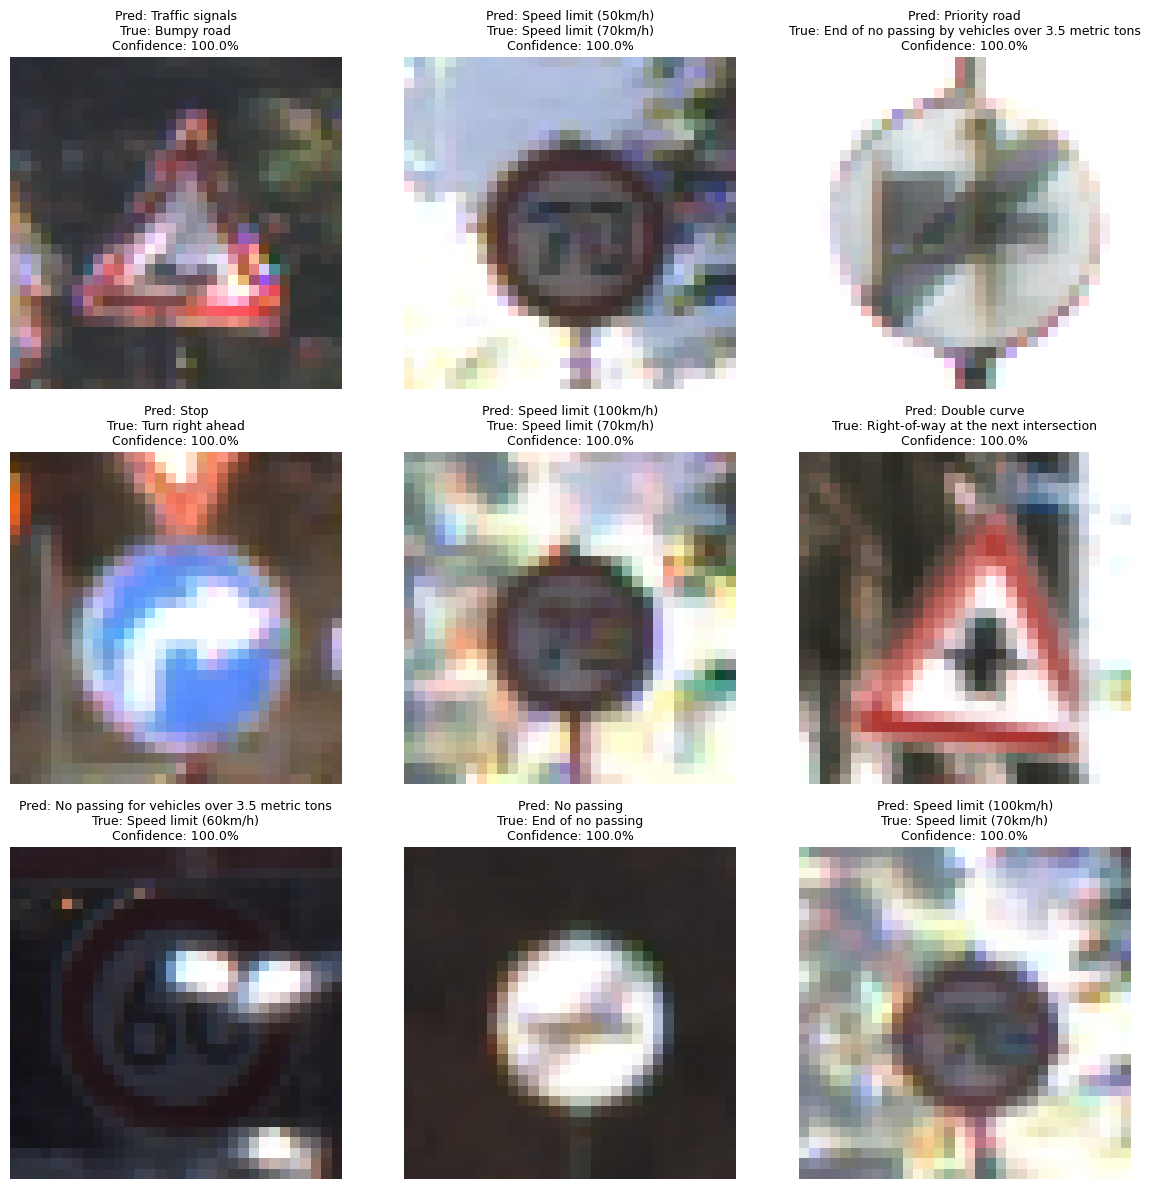

In [35]:
wrong_confidences = confidence_scores[incorrect_indices]

sorted_wrong = incorrect_indices[
    np.argsort(wrong_confidences)[::-1]
]

fig, axes = plt.subplots(3, 3, figsize=(12, 12))
axes = axes.ravel()

for i in range(9):
    idx = sorted_wrong[i]

    predicted_id = predicted_classes[idx]
    actual_id = y_true[idx]

    axes[i].imshow(X_test[idx])

    axes[i].set_title(
        f"Pred: {class_names[predicted_id]}\n"
        f"True: {class_names[actual_id]}\n"
        f"Confidence: {confidence_scores[idx]:.1f}%",
        fontsize=9
    )

    axes[i].axis("off")

plt.tight_layout()
plt.show()

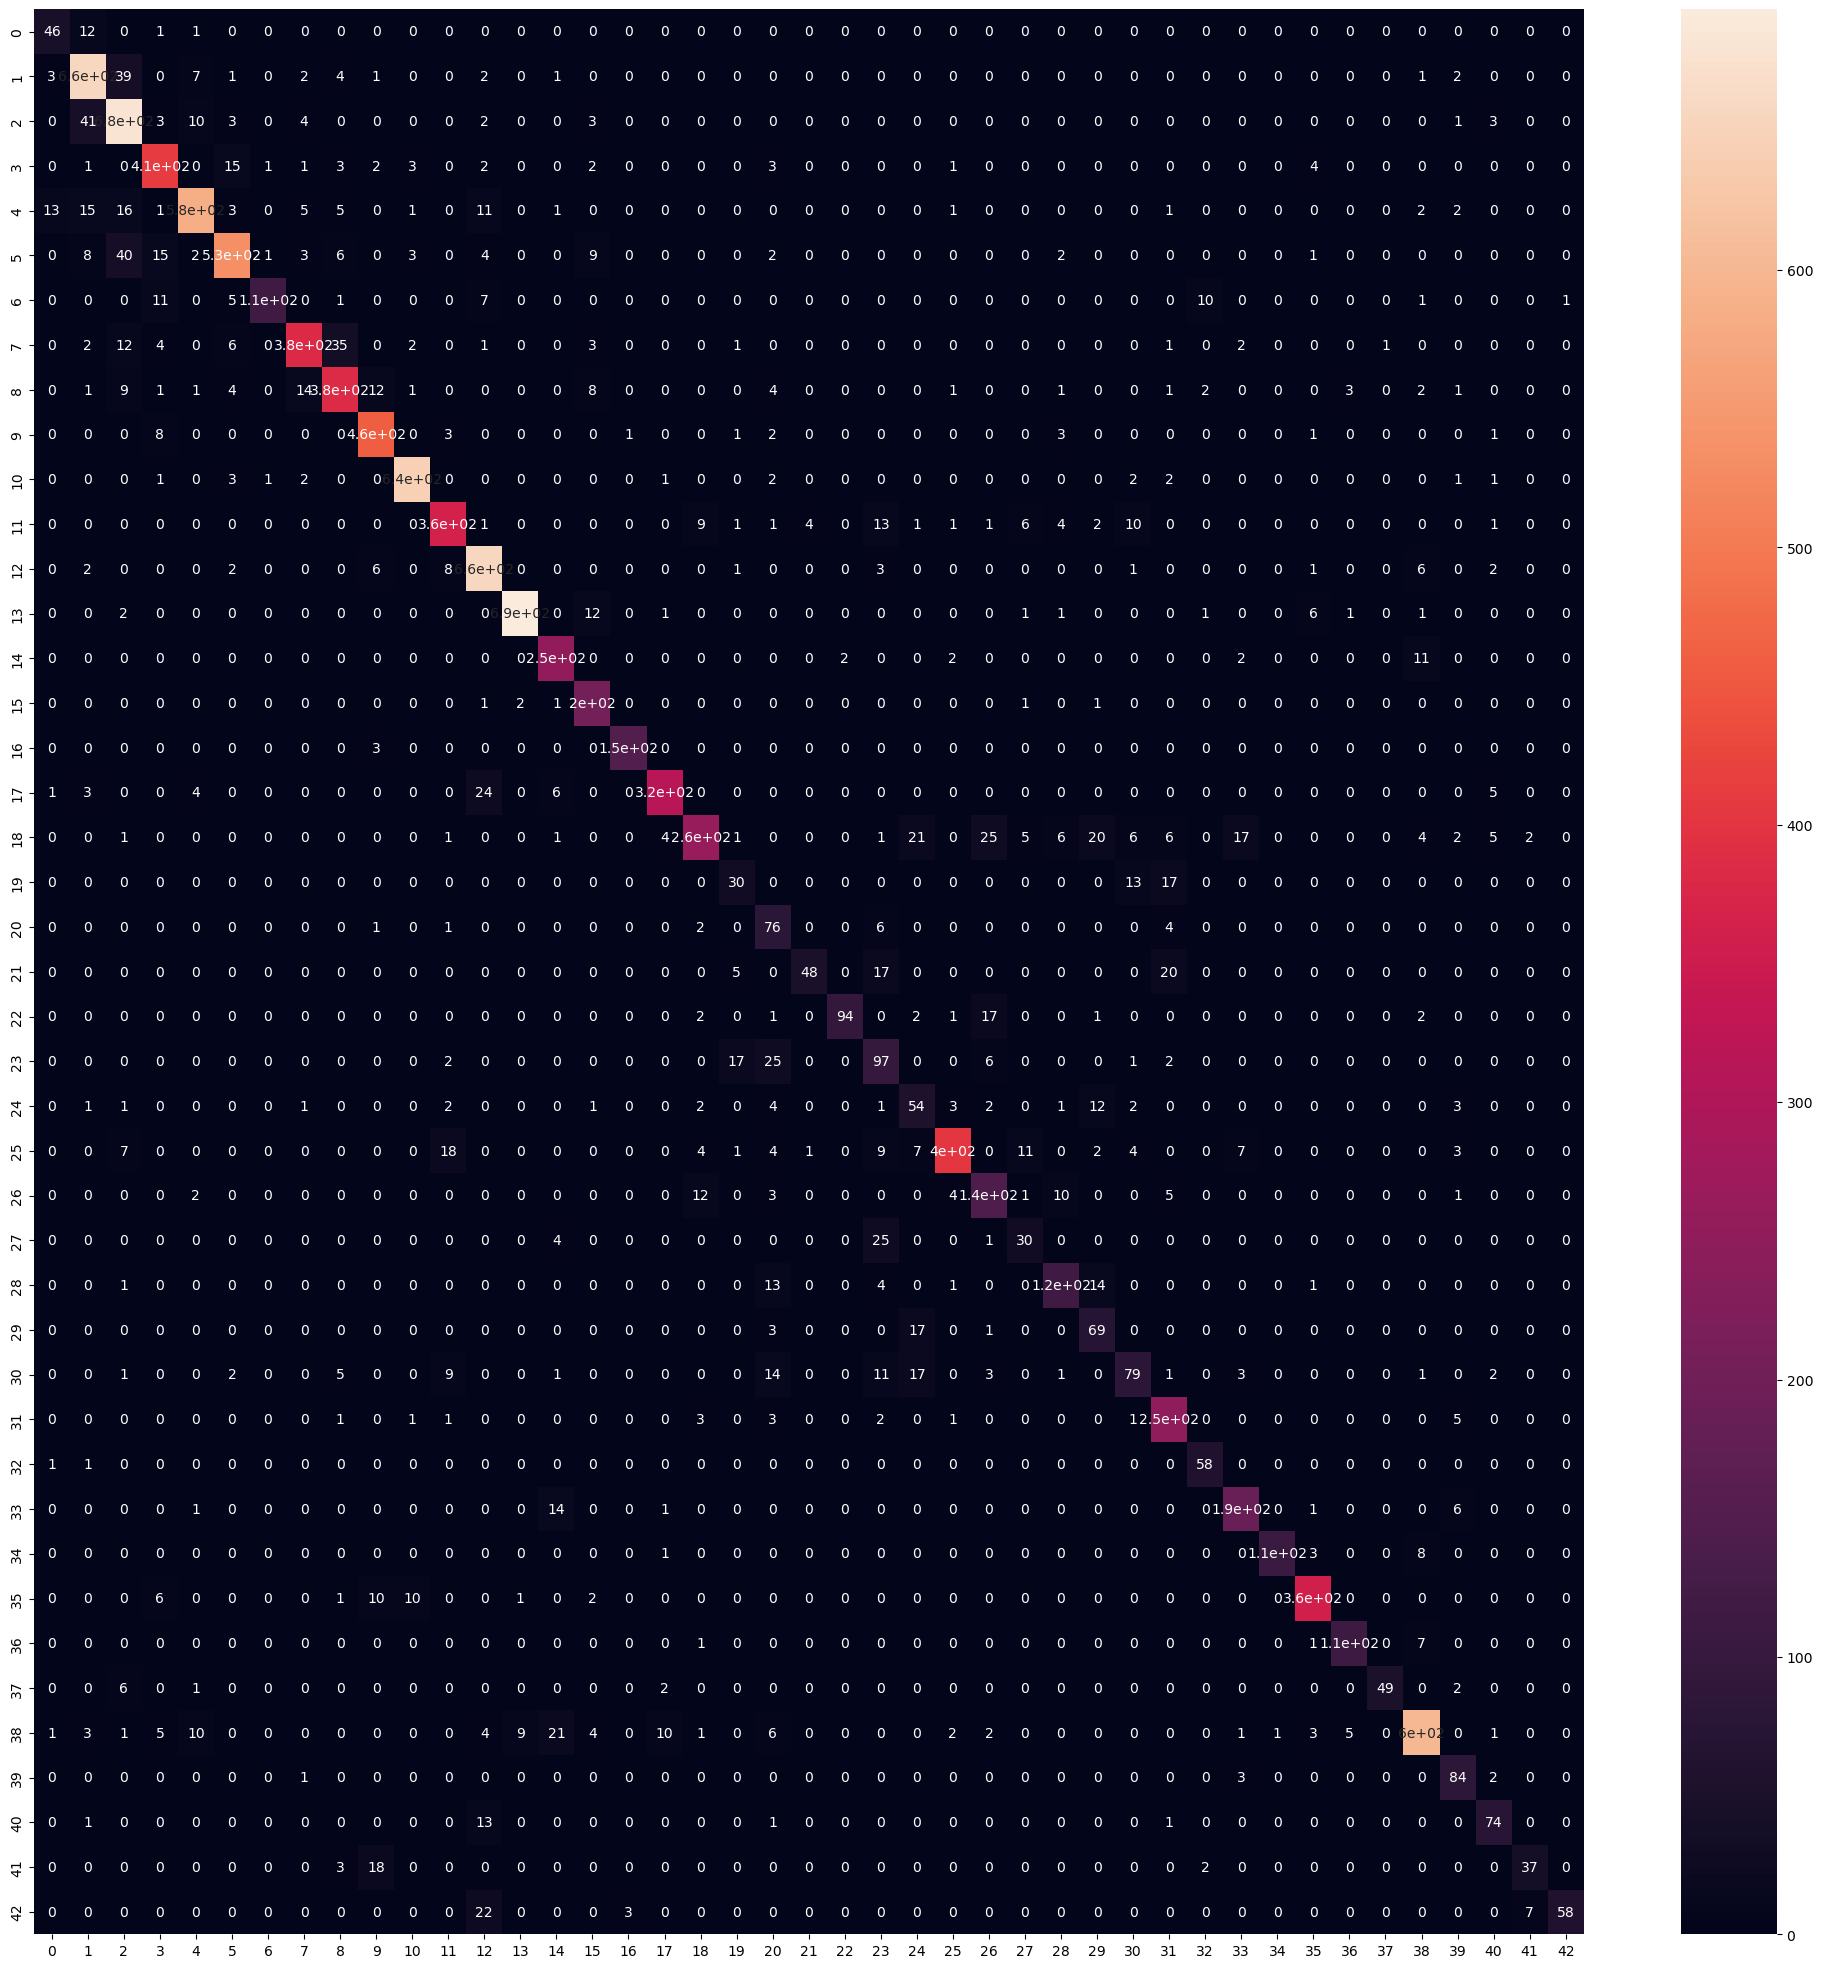

In [36]:
from sklearn.metrics import confusion_matrix
cm = confusion_matrix(y_true, predicted_classes)
plt.figure(figsize= (25, 25))
sns.heatmap(cm, annot = True)
plt.show()

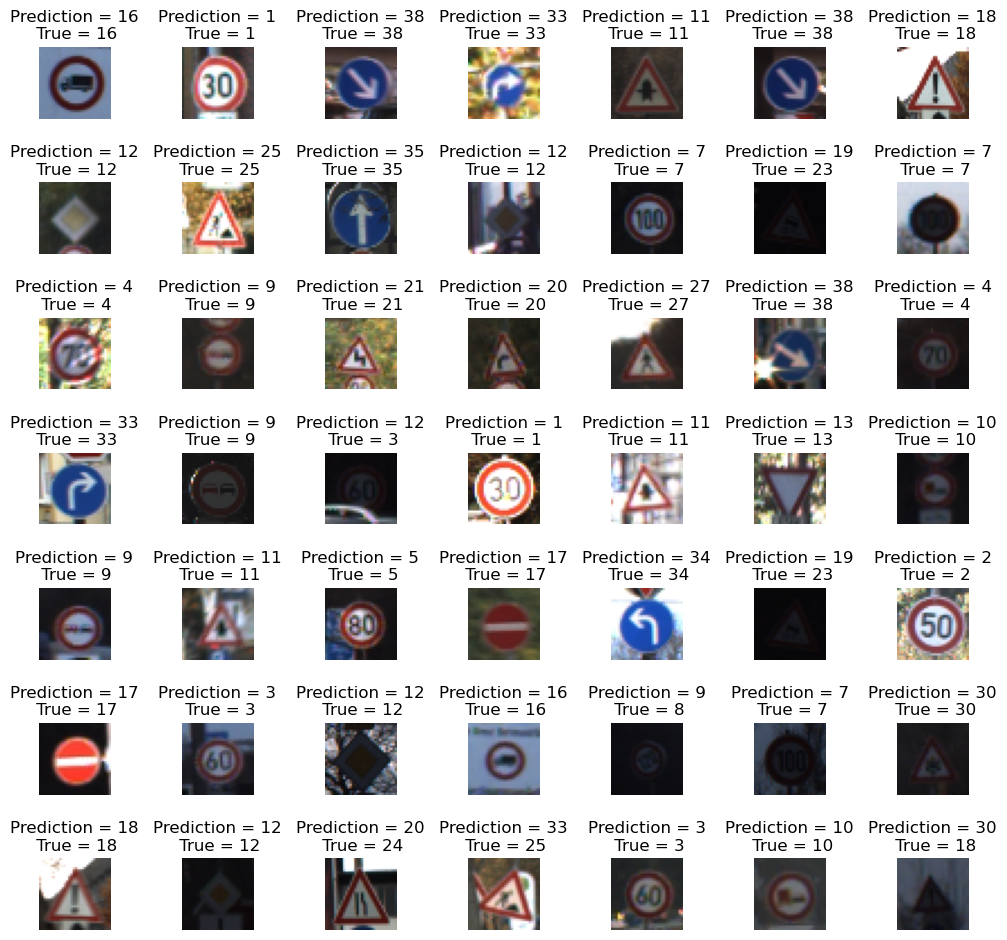

In [37]:
L = 7
W = 7

fig, axes = plt.subplots(L, W, figsize = (12, 12))
axes = axes.ravel()

for i in np.arange(0, L*W):
    axes[i].imshow(X_test[i])
    axes[i].set_title('Prediction = {}\n True = {}'.format(predicted_classes[i], y_true[i]))
    axes[i].axis('off')
plt.subplots_adjust(wspace= 1)

In [38]:
score = cnn_model.evaluate(X_test_gray_norm, y_test)

print('Test Loss:', score[0])
print('Test Accuracy: {:.2f}%'.format(score[1] * 100))

395/395 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8717 - loss: 1.1560
Test Loss: 1.155979037284851
Test Accuracy: 87.17%


In [39]:
print("Training samples:", X_train.shape[0])
print("Validation samples:", X_validation.shape[0])
print("Test samples:", X_test.shape[0])

print("Original image shape:", X_train.shape[1:])
print("Processed image shape:", X_train_gray_norm.shape[1:])

print("Number of classes:", len(np.unique(y_train)))

Training samples: 34799
Validation samples: 4410
Test samples: 12630
Original image shape: (32, 32, 3)
Processed image shape: (32, 32, 1)
Number of classes: 43


In [40]:
print("Minimum normalized value:", X_train_gray_norm.min())
print("Maximum normalized value:", X_train_gray_norm.max())

Minimum normalized value: -0.9713541666666666
Maximum normalized value: 0.9921875


# STEP 6: DATA AUGMENTATION

In [41]:
from keras import Sequential
from keras.layers import RandomRotation, RandomTranslation, RandomZoom

data_augmentation = Sequential([
    RandomRotation(0.05),
    RandomTranslation(
        height_factor=0.1,
        width_factor=0.1
    ),
    RandomZoom(0.1)
])

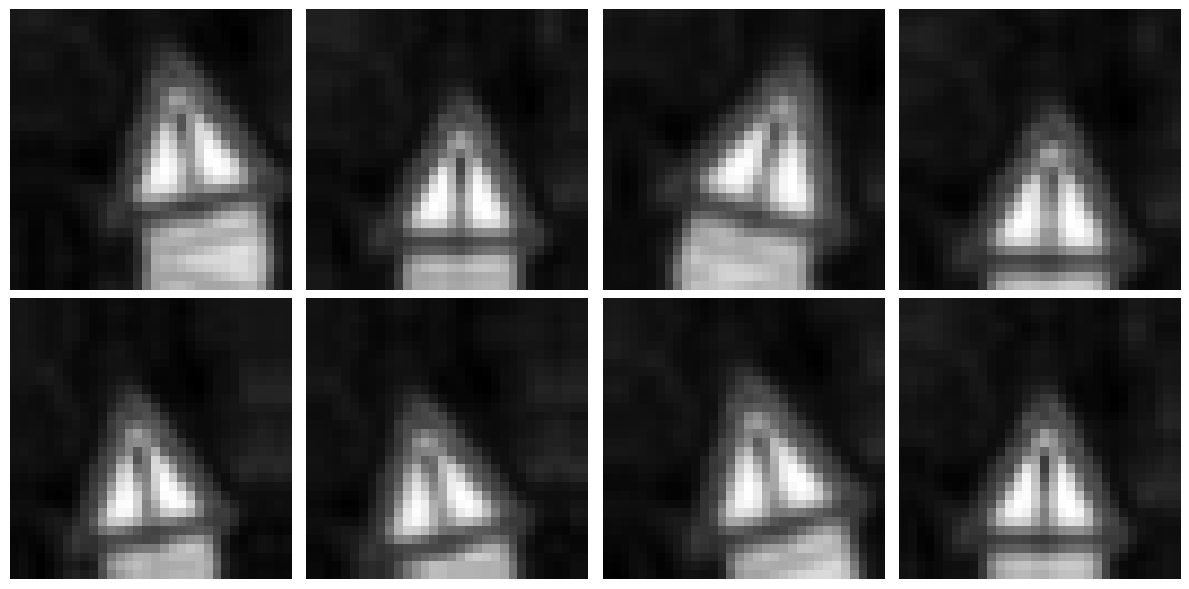

In [42]:
i = 100

sample_image = X_train_gray_norm[i]

sample_batch = np.expand_dims(sample_image, axis=0)

fig, axes = plt.subplots(2, 4, figsize=(12, 6))
axes = axes.ravel()

for j in range(8):

    augmented_image = data_augmentation(
        sample_batch,
        training=True
    )

    axes[j].imshow(
        augmented_image[0].numpy().squeeze(),
        cmap='gray'
    )

    axes[j].axis('off')

plt.tight_layout()
plt.show()

# STEP 6.1: LENET WITH DATA AUGMENTATION

In [43]:
cnn_model_augmented = Sequential()

# Data augmentation
cnn_model_augmented.add(data_augmentation)

# LeNet architecture
cnn_model_augmented.add(
    Conv2D(
        filters=6,
        kernel_size=(5, 5),
        activation='relu',
        input_shape=(32, 32, 1)
    )
)

cnn_model_augmented.add(AveragePooling2D(2, 2))

cnn_model_augmented.add(
    Conv2D(
        filters=16,
        kernel_size=(5, 5),
        activation='relu'
    )
)

cnn_model_augmented.add(AveragePooling2D(2, 2))

cnn_model_augmented.add(Flatten())

cnn_model_augmented.add(Dense(120, activation='relu'))
cnn_model_augmented.add(Dense(84, activation='relu'))

# 43 traffic sign classes
cnn_model_augmented.add(Dense(43, activation='softmax'))

C:\Users\amill\AppData\Roaming\Python\Python313\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [44]:
cnn_model_augmented.compile(
    optimizer=Adam(),
    loss=SparseCategoricalCrossentropy(),
    metrics=['accuracy']
)

In [45]:
cnn_model_augmented.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequential_1 (Sequential)       │ (1, 32, 32, 1)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (1, 28, 28, 6)         │           156 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ average_pooling2d_2             │ (1, 14, 14, 6)         │             0 │
│ (AveragePooling2D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (1, 10, 10, 16)        │         2,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ average_pooling2d_3             │ (1, 5, 5, 16)          │             0 │
│ (AveragePooling2D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (1, 400)               │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (1, 120)               │        48,120 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (1, 84)                │        10,164 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (1, 43)                │         3,655 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 64,511 (252.00 KB)

 Trainable params: 64,511 (252.00 KB)

 Non-trainable params: 0 (0.00 B)

In [46]:
history_augmented = cnn_model_augmented.fit(
    X_train_gray_norm,
    y_train,
    batch_size=500,
    epochs=50,
    verbose=1,
    validation_data=(
        X_validation_gray_norm,
        y_validation
    )
)

Epoch 1/50
70/70 ━━━━━━━━━━━━━━━━━━━━ 3s 26ms/step - accuracy: 0.1025 - loss: 3.3951 - val_accuracy: 0.1528 - val_loss: 3.2856
Epoch 2/50
70/70 ━━━━━━━━━━━━━━━━━━━━ 2s 24ms/step - accuracy: 0.2258 - loss: 2.8395 - val_accuracy: 0.3390 - val_loss: 2.3684
Epoch 3/50
70/70 ━━━━━━━━━━━━━━━━━━━━ 2s 23ms/step - accuracy: 0.3501 - loss: 2.3246 - val_accuracy: 0.4664 - val_loss: 1.8558
Epoch 4/50
70/70 ━━━━━━━━━━━━━━━━━━━━ 2s 23ms/step - accuracy: 0.4330 - loss: 2.0032 - val_accuracy: 0.5474 - val_loss: 1.5909
Epoch 5/50
70/70 ━━━━━━━━━━━━━━━━━━━━ 2s 23ms/step - accuracy: 0.4949 - loss: 1.7722 - val_accuracy: 0.5735 - val_loss: 1.3839
Epoch 6/50
70/70 ━━━━━━━━━━━━━━━━━━━━ 2s 27ms/step - accuracy: 0.5420 - loss: 1.5930 - val_accuracy: 0.6209 - val_loss: 1.2415
Epoch 7/50
70/70 ━━━━━━━━━━━━━━━━━━━━ 2s 26ms/step - accuracy: 0.5841 - loss: 1.4385 - val_accuracy: 0.6435 - val_loss: 1.1933
Epoch 8/50
70/70 ━━━━━━━━━━━━━━━━━━━━ 2s 27ms/step - accuracy: 0.6149 - loss: 1.3207 - val_accuracy: 0.6424 - v

In [47]:
augmented_score = cnn_model_augmented.evaluate(
    X_test_gray_norm,
    y_test
)

print("Augmented Model Test Loss:", augmented_score[0])
print(
    "Augmented Model Test Accuracy: {:.2f}%".format(
        augmented_score[1] * 100
    )
)

395/395 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8648 - loss: 0.6084
Augmented Model Test Loss: 0.608378529548645
Augmented Model Test Accuracy: 86.48%


# STEP 6.2: EVALUATE AUGMENTED MODEL

In [50]:
aug_predictions = cnn_model_augmented.predict(
    X_test_gray_norm
)

aug_predicted_classes = np.argmax(
    aug_predictions,
    axis=1
)

395/395 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step


In [51]:
from sklearn.metrics import classification_report

aug_report = classification_report(
    y_test,
    aug_predicted_classes,
    target_names=class_names,
    digits=4
)

print(aug_report)

                                                    precision    recall  f1-score   support

                              Speed limit (20km/h)     0.4730    0.5833    0.5224        60
                              Speed limit (30km/h)     0.8615    0.9333    0.8960       720
                              Speed limit (50km/h)     0.9182    0.8680    0.8924       750
                              Speed limit (60km/h)     0.8829    0.8044    0.8419       450
                              Speed limit (70km/h)     0.8933    0.8879    0.8906       660
                              Speed limit (80km/h)     0.7828    0.7095    0.7444       630
                       End of speed limit (80km/h)     0.9197    0.8400    0.8780       150
                             Speed limit (100km/h)     0.6737    0.7844    0.7248       450
                             Speed limit (120km/h)     0.7961    0.9111    0.8497       450
                                        No passing     0.8738    0.9521    0.91

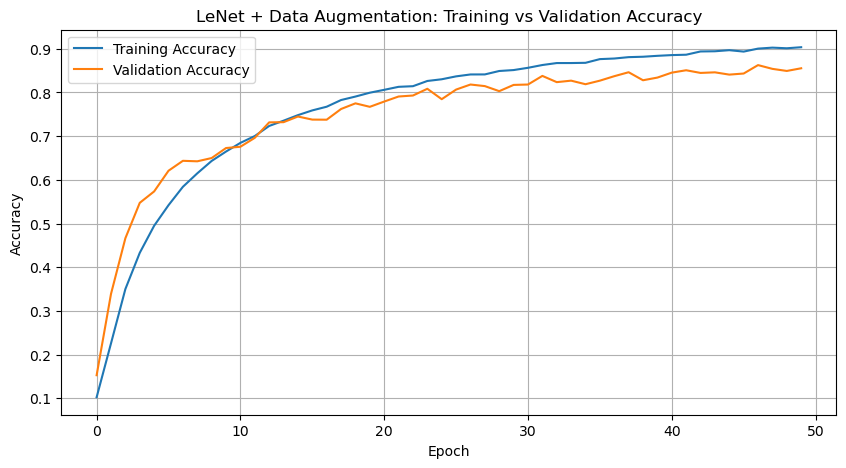

In [52]:
plt.figure(figsize=(10, 5))

plt.plot(
    history_augmented.history['accuracy'],
    label='Training Accuracy'
)

plt.plot(
    history_augmented.history['val_accuracy'],
    label='Validation Accuracy'
)

plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.title('LeNet + Data Augmentation: Training vs Validation Accuracy')

plt.legend()
plt.grid()
plt.show()

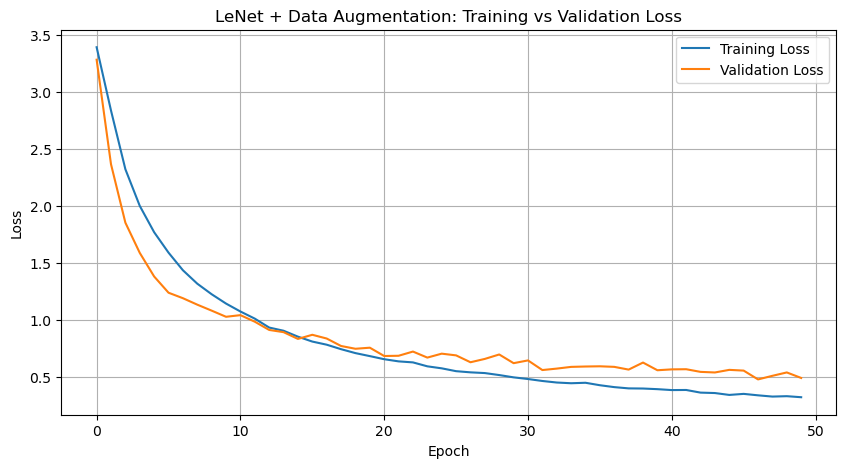

In [53]:
plt.figure(figsize=(10, 5))

plt.plot(
    history_augmented.history['loss'],
    label='Training Loss'
)

plt.plot(
    history_augmented.history['val_loss'],
    label='Validation Loss'
)

plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('LeNet + Data Augmentation: Training vs Validation Loss')

plt.legend()
plt.grid()
plt.show()


# STEP 7: IMPROVED CNN MODEL

In [61]:
from keras.layers import (
    Conv2D,
    MaxPooling2D,
    Dense,
    Flatten,
    Dropout,
    BatchNormalization,
    Activation
)

In [62]:
improved_cnn = Sequential()

# Data augmentation
improved_cnn.add(data_augmentation)

# -------------------------
# Convolution Block 1
# -------------------------

improved_cnn.add(
    Conv2D(
        32,
        (3, 3),
        padding='same',
        input_shape=(32, 32, 1)
    )
)

improved_cnn.add(BatchNormalization())
improved_cnn.add(keras.layers.Activation('relu'))

improved_cnn.add(
    Conv2D(
        32,
        (3, 3),
        padding='same',
        activation='relu'
    )
)

improved_cnn.add(MaxPooling2D((2, 2)))
improved_cnn.add(Dropout(0.25))


# -------------------------
# Convolution Block 2
# -------------------------

improved_cnn.add(
    Conv2D(
        64,
        (3, 3),
        padding='same'
    )
)

improved_cnn.add(BatchNormalization())
improved_cnn.add(keras.layers.Activation('relu'))

improved_cnn.add(
    Conv2D(
        64,
        (3, 3),
        padding='same',
        activation='relu'
    )
)

improved_cnn.add(MaxPooling2D((2, 2)))
improved_cnn.add(Dropout(0.25))


# -------------------------
# Classification
# -------------------------

improved_cnn.add(Flatten())

improved_cnn.add(
    Dense(
        256,
        activation='relu'
    )
)

improved_cnn.add(Dropout(0.5))

improved_cnn.add(
    Dense(
        43,
        activation='softmax'
    )
)

In [63]:
from keras.callbacks import EarlyStopping

In [64]:
early_stopping = EarlyStopping(
    monitor='val_loss',
    patience=7,
    restore_best_weights=True
)

In [65]:
improved_cnn.compile(
    optimizer=Adam(),
    loss=SparseCategoricalCrossentropy(),
    metrics=['accuracy']
)

In [66]:
improved_cnn.summary()

Model: "sequential_6"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequential_1 (Sequential)       │ (1, 32, 32, 1)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_10 (Conv2D)              │ (1, 32, 32, 32)        │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (1, 32, 32, 32)        │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (1, 32, 32, 32)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_11 (Conv2D)              │ (1, 32, 32, 32)        │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (1, 16, 16, 32)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (1, 16, 16, 32)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_12 (Conv2D)              │ (1, 16, 16, 64)        │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (1, 16, 16, 64)        │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (1, 16, 16, 64)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_13 (Conv2D)              │ (1, 16, 16, 64)        │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (1, 8, 8, 64)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (1, 8, 8, 64)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_3 (Flatten)             │ (1, 4096)              │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (1, 256)               │     1,048,832 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (1, 256)               │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (1, 43)                │        11,051 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,125,259 (4.29 MB)

 Trainable params: 1,125,067 (4.29 MB)

 Non-trainable params: 192 (768.00 B)

In [67]:
history_improved = improved_cnn.fit(
    X_train_gray_norm,
    y_train,

    batch_size=128,
    epochs=50,

    validation_data=(
        X_validation_gray_norm,
        y_validation
    ),

    callbacks=[early_stopping],

    verbose=1
)

Epoch 1/50
272/272 ━━━━━━━━━━━━━━━━━━━━ 36s 123ms/step - accuracy: 0.2854 - loss: 2.6020 - val_accuracy: 0.3812 - val_loss: 2.2708
Epoch 2/50
272/272 ━━━━━━━━━━━━━━━━━━━━ 42s 156ms/step - accuracy: 0.7155 - loss: 0.9146 - val_accuracy: 0.8850 - val_loss: 0.3540
Epoch 3/50
272/272 ━━━━━━━━━━━━━━━━━━━━ 41s 150ms/step - accuracy: 0.8522 - loss: 0.4741 - val_accuracy: 0.9190 - val_loss: 0.2307
Epoch 4/50
272/272 ━━━━━━━━━━━━━━━━━━━━ 41s 152ms/step - accuracy: 0.8969 - loss: 0.3286 - val_accuracy: 0.9605 - val_loss: 0.1139
Epoch 5/50
272/272 ━━━━━━━━━━━━━━━━━━━━ 78s 137ms/step - accuracy: 0.9236 - loss: 0.2480 - val_accuracy: 0.9741 - val_loss: 0.0749
Epoch 6/50
272/272 ━━━━━━━━━━━━━━━━━━━━ 42s 153ms/step - accuracy: 0.9368 - loss: 0.2042 - val_accuracy: 0.9655 - val_loss: 0.0994
Epoch 7/50
272/272 ━━━━━━━━━━━━━━━━━━━━ 42s 153ms/step - accuracy: 0.9469 - loss: 0.1707 - val_accuracy: 0.9814 - val_loss: 0.0573
Epoch 8/50
272/272 ━━━━━━━━━━━━━━━━━━━━ 42s 153ms/step - accuracy: 0.9507 - loss: 0

In [68]:
print("Epochs actually trained:", len(history_improved.history['loss']))

Epochs actually trained: 24


In [69]:
improved_score = improved_cnn.evaluate(
    X_test_gray_norm,
    y_test
)

print("Improved CNN Test Loss:", improved_score[0])
print(
    "Improved CNN Test Accuracy: {:.2f}%".format(
        improved_score[1] * 100
    )
)

395/395 ━━━━━━━━━━━━━━━━━━━━ 5s 12ms/step - accuracy: 0.9707 - loss: 0.1444
Improved CNN Test Loss: 0.14442652463912964
Improved CNN Test Accuracy: 97.07%


In [70]:
improved_predictions = improved_cnn.predict(
    X_test_gray_norm
)

improved_predicted_classes = np.argmax(
    improved_predictions,
    axis=1
)

395/395 ━━━━━━━━━━━━━━━━━━━━ 5s 11ms/step


In [71]:
from sklearn.metrics import classification_report

improved_report = classification_report(
    y_test,
    improved_predicted_classes,
    target_names=class_names,
    digits=4
)

print(improved_report)

                                                    precision    recall  f1-score   support

                              Speed limit (20km/h)     0.9375    1.0000    0.9677        60
                              Speed limit (30km/h)     0.9634    0.9861    0.9746       720
                              Speed limit (50km/h)     0.9676    0.9960    0.9816       750
                              Speed limit (60km/h)     1.0000    0.9844    0.9922       450
                              Speed limit (70km/h)     1.0000    0.9788    0.9893       660
                              Speed limit (80km/h)     0.9888    0.9794    0.9841       630
                       End of speed limit (80km/h)     0.8242    1.0000    0.9036       150
                             Speed limit (100km/h)     0.9888    0.9822    0.9855       450
                             Speed limit (120km/h)     0.9804    1.0000    0.9901       450
                                        No passing     0.9796    0.9979    0.98

In [72]:
improved_confidence = np.max(
    improved_predictions,
    axis=1
) * 100

improved_incorrect_indices = np.where(
    improved_predicted_classes != y_test
)[0]

correct_count = np.sum(
    improved_predicted_classes == y_test
)

print("Total test images:", len(y_test))
print("Correct predictions:", correct_count)
print("Incorrect predictions:", len(improved_incorrect_indices))
print(
    "Accuracy:",
    f"{correct_count / len(y_test) * 100:.2f}%"
)

Total test images: 12630
Correct predictions: 12260
Incorrect predictions: 370
Accuracy: 97.07%


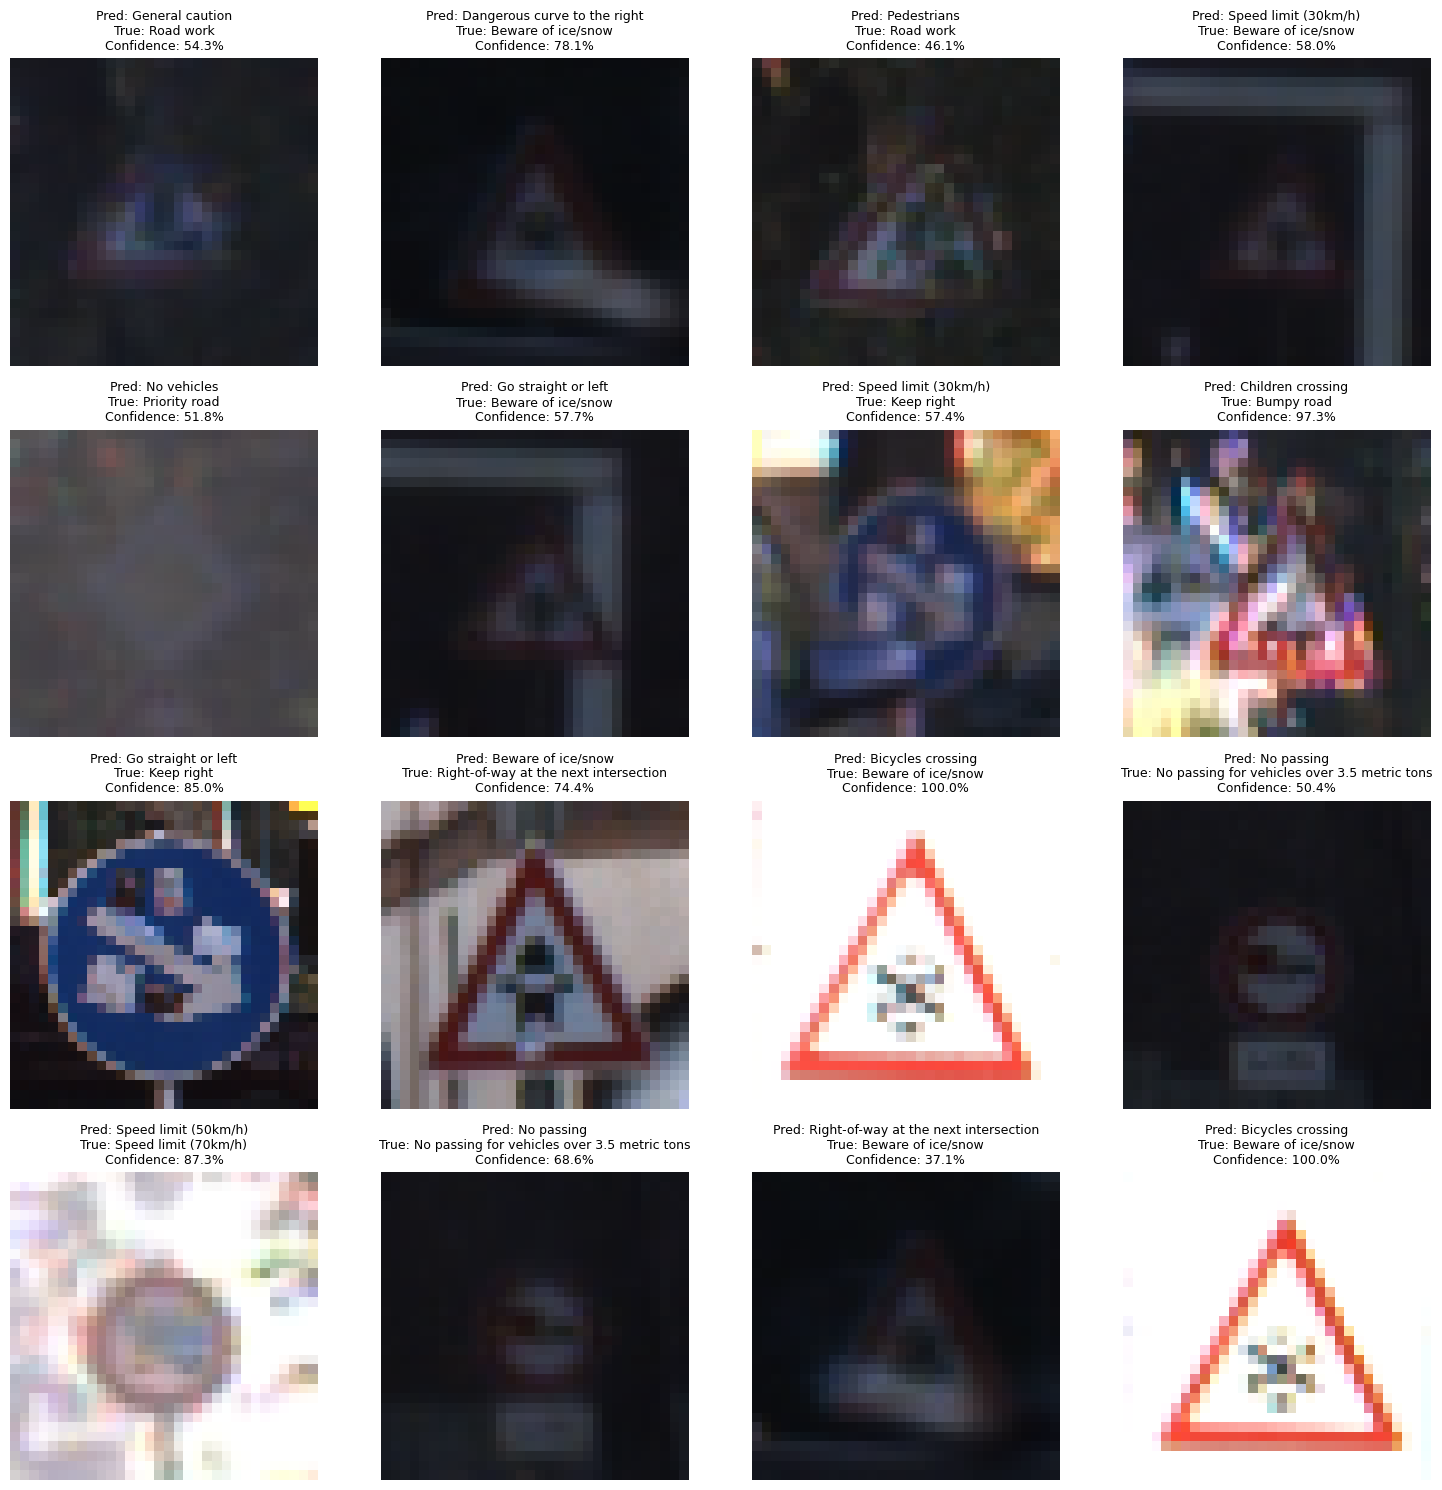

In [73]:
fig, axes = plt.subplots(4, 4, figsize=(15, 15))
axes = axes.ravel()

for i in range(16):

    idx = improved_incorrect_indices[i]

    predicted_id = improved_predicted_classes[idx]
    actual_id = y_test[idx]

    axes[i].imshow(X_test[idx])

    axes[i].set_title(
        f"Pred: {class_names[predicted_id]}\n"
        f"True: {class_names[actual_id]}\n"
        f"Confidence: {improved_confidence[idx]:.1f}%",
        fontsize=9
    )

    axes[i].axis("off")

plt.tight_layout()
plt.show()

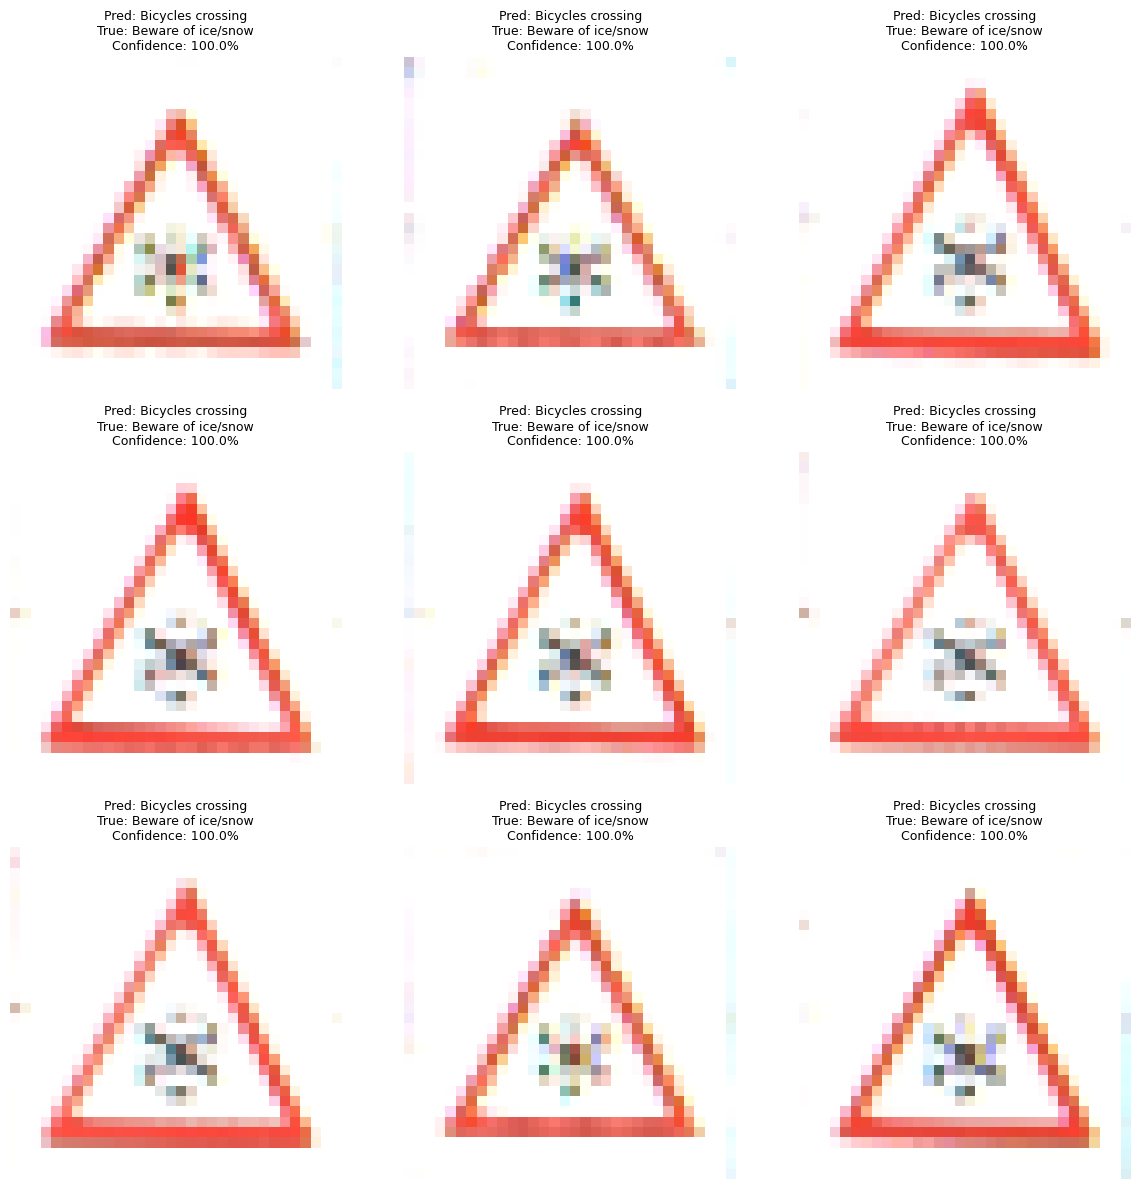

In [74]:
wrong_confidences = improved_confidence[
    improved_incorrect_indices
]

sorted_wrong_indices = improved_incorrect_indices[
    np.argsort(wrong_confidences)[::-1]
]

fig, axes = plt.subplots(3, 3, figsize=(12, 12))
axes = axes.ravel()

for i in range(9):

    idx = sorted_wrong_indices[i]

    predicted_id = improved_predicted_classes[idx]
    actual_id = y_test[idx]

    axes[i].imshow(X_test[idx])

    axes[i].set_title(
        f"Pred: {class_names[predicted_id]}\n"
        f"True: {class_names[actual_id]}\n"
        f"Confidence: {improved_confidence[idx]:.1f}%",
        fontsize=9
    )

    axes[i].axis("off")

plt.tight_layout()
plt.show()

# STEP 8: SAVE THE BEST MODEL

In [76]:
improved_cnn.save("traffic_sign_cnn.keras")

print("Model saved successfully!")

Model saved successfully!


In [77]:
from keras.models import load_model

model = load_model("traffic_sign_cnn.keras")

In [80]:
import json

with open("class_names.json", "w") as f:
    json.dump(class_names, f)

print("Class names saved successfully!")

Class names saved successfully!


In [81]:
import sys

print(sys.version)
print(sys.executable)

3.13.5 | packaged by Anaconda, Inc. | (main, Jun 12 2025, 16:37:03) [MSC v.1929 64 bit (AMD64)]
c:\ProgramData\anaconda3\python.exe
